# Inferring sparse feeding controls from glucose

We compare NumPyro NUTS and joint Adaptive Metropolis on the same fixed-key EnKF posterior. The unknowns are insulin sensitivity $S$, secretion $B$, and 24 positive feeding doses. Eight glucose measurements constrain the broad timing and amount of feeding. Nearby bins can yield similar glucose trajectories.

For a dose $a_j$ in the five-minute bin starting at $5j$, the input rate $u(t)$ is $a_j/5$ in that bin and zero from minute 120 onward. The fasting initial state is $(G,J,Q)_0=(5,0,0)$.

$$
\begin{aligned}
dG &= [0.035Q-0.015(G-5)-SJG]dt+0.025\,dW_G,\\
dJ &= [B(G-5)-0.08J]dt+0.12\,dW_J,\\
dQ &= [u(t)-0.035Q]dt,\\
y_i &\sim \mathcal{N}(G(t_i),0.25^2),\\
\log S &\sim\mathcal{N}(\log 0.001,0.7^2),\qquad
\log B\sim\mathcal{N}(\log 0.8,0.7^2).
\end{aligned}
$$

Each dose has an independent positive regularized horseshoe prior with fixed global scale $\tau=0.20$ and slab scale $c=6$. Conditional on $\lambda_j\sim\operatorname{HalfCauchy}(1)$, the dose is half-normal with scale $c\tau\lambda_j/\sqrt{c^2+\tau^2\lambda_j^2}$. We integrate out each local scale, leaving 26 continuous coordinates. The posterior probability $P(a_j>1\mid y)$ refers to a dose threshold of one gut-load unit. [Regularized horseshoe formulation](https://arxiv.org/abs/1707.01694)

In [1]:
import numpyro

numpyro.set_host_device_count(4)

import json
import time
from importlib.metadata import version
from pathlib import Path

import jax

jax.config.update("jax_enable_x64", True)

import arviz as az
import blackjax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist
import pandas as pd
from IPython.display import display
from jax.flatten_util import ravel_pytree
from numpyro.infer import MCMC, NUTS, Predictive, init_to_median
from numpyro.infer.util import initialize_model, log_density
from scipy.special import roots_legendre

import dynestyx as dsx
from dynestyx.inference.configs.discretizer import EulerMaruyamaConfig
from dynestyx.inference.configs.filter import EnKFConfig
from dynestyx.inference.configs.mcmc import AdaptiveMetropolisConfig
from dynestyx.inference.mcmc import MCMCInference

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dynestyx").is_dir())
OUT = ROOT / "examples/ogtt_sde/results/feeding_benchmark"
OUT.mkdir(parents=True, exist_ok=True)

N_BINS, BIN_MINUTES = 24, 5.0
BIN_EDGES = BIN_MINUTES * jnp.arange(N_BINS + 1, dtype=jnp.float64)
TAU, SLAB = 0.20, 6.0
DOSE_THRESHOLD = 1.0
TRUE_S, TRUE_B = 0.001, 0.8
TRUE_DOSE = jnp.zeros(N_BINS).at[jnp.array([1, 10, 20])].set(jnp.array([7.0, 6.0, 5.0]))
OBS_TIMES = jnp.array([0.0, 15.0, 30.0, 45.0, 60.0, 90.0, 120.0, 180.0])
OBS_SD = 0.25
ENSEMBLE, FILTER_DT, SIM_DT = 20, 0.5, 0.025
SIM_SEED, FILTER_SEED = 12, 0
NUTS_SEED, MH_SEED = 42, 43
NUM_CHAINS = 4

devices = jax.local_devices()
print("JAX devices:", devices)
if len(devices) < NUM_CHAINS:
    raise RuntimeError(
        f"Expected at least {NUM_CHAINS} JAX devices, found {len(devices)}. "
        "Restart the kernel and run this cell first."
    )

NUTS_WARMUP, NUTS_DRAWS = 500, 2000
MH_WARMUP, MH_DRAWS = 1000, 4000
NUTS_TARGET, MH_TARGET, MH_INITIAL_SCALE = 0.9, 0.234, 0.1
INIT = init_to_median(num_samples=15)
SITES = ("sensitivity", "secretion", "feeding_dose")

VERSIONS = {
    name: version(name)
    for name in ("arviz", "blackjax", "cuthbert", "dynestyx", "jax", "numpyro")
}


JAX devices: [CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3)]


## Marginal dose prior and controlled dynamics

On the log-local-scale axis, $r=\log\lambda$ has density $1/(\pi\cosh r)$. Gauss–Legendre quadrature on $[-28,28]$ approximates the integral as a weighted half-normal mixture. NumPyro sums over the mixture components in its log density. The samplers work in unconstrained log-dose coordinates.

The control arrays follow the simulation or filter grid. At a bin boundary, the new rate applies to the interval that starts there.

In [2]:
def marginal_dose_prior(num_nodes):
    nodes, weights = roots_legendre(num_nodes)
    r = 28.0 * jnp.asarray(nodes)
    logits = jnp.log(weights) - jnp.logaddexp(r, -r)
    h = TAU * jnp.exp(r)
    scales = SLAB * (h / jnp.hypot(SLAB, h))
    return dist.MixtureSameFamily(dist.Categorical(logits=logits), dist.HalfNormal(scales))


dose_prior = marginal_dose_prior(320)
reference_prior = marginal_dose_prior(768)


def check_prior(lower, upper):
    log_doses = jnp.linspace(np.log(lower), np.log(upper), 401)

    def evaluate(prior):
        def log_density_on_log_scale(log_dose):
            return prior.log_prob(jnp.exp(log_dose)) + log_dose

        return jax.vmap(jax.value_and_grad(log_density_on_log_scale))(log_doses)

    values, slopes = evaluate(dose_prior)
    ref_values, ref_slopes = evaluate(reference_prior)
    np.testing.assert_allclose(values, ref_values, atol=1e-6, rtol=0)
    np.testing.assert_allclose(slopes, ref_slopes, atol=1e-5, rtol=0)
    return {
        "dose_range": [float(lower), float(upper)],
        "max_log_density_error": float(jnp.max(jnp.abs(values - ref_values))),
        "max_log_dose_gradient_error": float(jnp.max(jnp.abs(slopes - ref_slopes))),
    }


prior_check = check_prior(1e-8, 40.0)
print(prior_check)


def control_rates(times, dose):
    bins = jnp.searchsorted(BIN_EDGES[1:], times, side="right")
    rates = jnp.concatenate([dose / BIN_MINUTES, jnp.zeros_like(dose[:1])])
    return rates[bins, None]


def controlled_path(s, b, dose, *, obs_times=None, obs_values=None, predict_times=None):
    def drift(x, u, t):
        g, j, q = x
        return jnp.array([
            0.035 * q - 0.015 * (g - 5.0) - s * j * g,
            b * (g - 5.0) - 0.08 * j,
            u[0] - 0.035 * q,
        ])

    dynamics = dsx.DynamicalModel(
        initial_condition=dist.Delta(jnp.array([5.0, 0.0, 0.0]), event_dim=1),
        state_evolution=dsx.ContinuousTimeStateEvolution(
            drift=drift,
            diffusion=dsx.FullDiffusion(jnp.array([[0.025, 0.0], [0.0, 0.12], [0.0, 0.0]])),
        ),
        observation_model=dsx.LinearGaussianObservation(
            H=jnp.array([[1.0, 0.0, 0.0]]), R=jnp.array([[OBS_SD**2]]),
        ),
        control_dim=1,
    )
    times = obs_times if predict_times is None else predict_times
    return dsx.sample(
        "ogtt", dynamics, obs_times=obs_times, obs_values=obs_values,
        predict_times=predict_times, ctrl_times=times, ctrl_values=control_rates(times, dose),
    )


def feeding_model(obs_times=None, obs_values=None, ctrl_times=None, ctrl_values=None):
    s = numpyro.sample("sensitivity", dist.LogNormal(jnp.log(TRUE_S), 0.7))
    b = numpyro.sample("secretion", dist.LogNormal(jnp.log(TRUE_B), 0.7))
    with numpyro.plate("feeding_bin", N_BINS):
        dose = numpyro.sample("feeding_dose", dose_prior)
    return controlled_path(s, b, dose, obs_times=obs_times, obs_values=obs_values)

{'dose_range': [1e-08, 40.0], 'max_log_density_error': 2.2448175762690425e-07, 'max_log_dose_gradient_error': 5.0906016768603735e-06}


## Simulate data and verify the common target

Simulate the SDE at a finer step than the filter. The dense trajectory is synthetic truth. Only the eight scheduled glucose values enter the likelihood. The remaining steps on the filter grid carry missing observations. Fixing the ensemble key gives both samplers the same deterministic approximation to the marginal likelihood.

In [3]:
sim_times = jnp.arange(721) * 0.25
fine_times = jnp.arange(361) * FILTER_DT

# Check the last bin, including the switch to zero at minute 120.
pulse = jnp.zeros(N_BINS).at[-1].set(7.0)
for times in (sim_times, fine_times):
    rates = control_rates(times, pulse)[:, 0]
    np.testing.assert_array_equal(rates > 0, (times >= 115) & (times < 120))
    np.testing.assert_allclose(jnp.sum(rates[:-1] * jnp.diff(times)), 7.0, rtol=0, atol=1e-12)


def simulate(predict_times):
    return controlled_path(TRUE_S, TRUE_B, TRUE_DOSE, predict_times=predict_times)


with dsx.SDESimulator(dsx.SDESimulatorConfig(dt0=SIM_DT)):
    simulated = Predictive(simulate, num_samples=1)(jr.PRNGKey(SIM_SEED), sim_times)
true_states = simulated["ogtt_states"][0, 0]
sim_indices = np.searchsorted(sim_times, OBS_TIMES)
obs_indices = np.searchsorted(fine_times, OBS_TIMES)
np.testing.assert_array_equal(sim_times[sim_indices], OBS_TIMES)
np.testing.assert_array_equal(fine_times[obs_indices], OBS_TIMES)
observations = simulated["ogtt_observations"][0, 0, sim_indices]
fine_y = jnp.full((fine_times.size, 1), jnp.nan).at[obs_indices].set(observations)

np.savez_compressed(
    OUT / "data.npz", times=sim_times, states=true_states, obs_times=OBS_TIMES,
    observations=observations, bin_edges=BIN_EDGES, true_doses=TRUE_DOSE,
)


def filter_context():
    return dsx.Filter(EnKFConfig(
        n_particles=ENSEMBLE, crn_seed=jr.PRNGKey(FILTER_SEED), warn=False,
        record_filtered_states_mean=False, record_filtered_states_cov=False,
        record_filtered_particles=False, include_predicted_observations=False,
        record_predicted_observations_mean=False, record_predicted_observations_cov=False,
        record_predicted_observations_ensemble=False,
    ))


def discretizer():
    return dsx.Discretizer(EulerMaruyamaConfig(covariance_jitter=1e-12))


model_kwargs = {"obs_times": fine_times, "obs_values": fine_y}
with filter_context(), discretizer():
    model_info = initialize_model(
        jr.PRNGKey(0), feeding_model, model_kwargs=model_kwargs,
        init_strategy=INIT, forward_mode_differentiation=True,
    )
    flat_init, unravel = ravel_pytree(model_info.param_info.z)
    assert set(model_info.param_info.z) == set(SITES)
    assert flat_init.size == N_BINS + 2
    params = model_info.postprocess_fn(model_info.param_info.z)
    log_targets = [
        log_density(numpyro.handlers.seed(feeding_model, key), (), model_kwargs, params)[0]
        for key in (0, 123)
    ]
    assert np.isfinite(log_targets).all()
    np.testing.assert_allclose(*log_targets, atol=1e-12, rtol=0)

    def potential(flat):
        return model_info.potential_fn(unravel(flat))

    probe_points = jnp.stack([flat_init, flat_init + 0.25 * jr.normal(jr.PRNGKey(1), flat_init.shape)])
    forward = jax.jit(jax.vmap(jax.jacfwd(potential)))(probe_points)
    assert np.isfinite(forward).all()
    use_forward_mode = False
    gradient_error = None
    try:
        reverse = jax.jit(jax.vmap(jax.grad(potential)))(probe_points)
        np.testing.assert_allclose(reverse, forward, atol=1e-7, rtol=1e-6)
        gradient_error = float(jnp.max(jnp.abs(forward - reverse)))
    except (ValueError, NotImplementedError, AssertionError) as error:
        use_forward_mode = True
        print(f"Using forward-mode differentiation: {error}")

print(f"Shared log density: {float(log_targets[0]):.6f}")
print("NUTS gradient mode:", "forward" if use_forward_mode else "reverse")
print("Maximum gradient difference:", gradient_error)

Shared log density: -57.047246
NUTS gradient mode: reverse
Maximum gradient difference: 1.4210854715202004e-14


## Run the samplers

Both use four chains and independent prior-median initialization. The timer includes compilation, warmup, and retained draws. NUTS runs chains sequentially. Adaptive Metropolis batches chains on the available device. Bulk ESS per second therefore compares these configured runs on this machine.

NUTS shows warmup and sampling progress. Adaptive Metropolis shows progress across its batched transitions. The latter uses the BlackJAX progress extra (`pip install 'blackjax[progress]>=1.7.1'`). The reported times include progress display overhead.

In [4]:
start = time.perf_counter()
with filter_context(), discretizer():
    nuts = MCMC(
        NUTS(
            feeding_model, dense_mass=True, target_accept_prob=NUTS_TARGET,
            forward_mode_differentiation=use_forward_mode, init_strategy=INIT,
        ),
        num_warmup=NUTS_WARMUP, num_samples=NUTS_DRAWS, num_chains=NUM_CHAINS,
        progress_bar=True,
    )
    nuts.run(jr.PRNGKey(NUTS_SEED), **model_kwargs, extra_fields=("diverging", "accept_prob", "num_steps"))
    nuts_samples = nuts.get_samples(group_by_chain=True)
    nuts_extra = nuts.get_extra_fields(group_by_chain=True)
    jax.block_until_ready((nuts_samples, nuts_extra))
nuts_seconds = time.perf_counter() - start
nuts_diagnostics = {
    "chain_execution": "sequential",
    "gradient_mode": "forward" if use_forward_mode else "reverse",
    "seconds": nuts_seconds,
    "divergences_per_chain": np.asarray(nuts_extra["diverging"]).sum(axis=1).tolist(),
    "mean_acceptance_per_chain": np.asarray(nuts_extra["accept_prob"]).mean(axis=1).tolist(),
    "mean_leapfrog_steps_per_chain": np.asarray(nuts_extra["num_steps"]).mean(axis=1).tolist(),
}
np.savez_compressed(OUT / "nuts_samples.npz", **{name: nuts_samples[name] for name in SITES})
(OUT / "nuts_run.json").write_text(json.dumps(nuts_diagnostics, indent=2))
print(nuts_diagnostics)

  0%|          | 0/2500 [00:00<?, ?it/s]

  0%|          | 0/2500 [00:00<?, ?it/s]

  0%|          | 0/2500 [00:00<?, ?it/s]

  0%|          | 0/2500 [00:00<?, ?it/s]

{'chain_execution': 'sequential', 'gradient_mode': 'reverse', 'seconds': 2381.295415666995, 'divergences_per_chain': [0, 1, 0, 0], 'mean_acceptance_per_chain': [0.9489882180128026, 0.8852343339921681, 0.9303931329004368, 0.95483219213208], 'mean_leapfrog_steps_per_chain': [81.176, 61.689, 87.8, 99.912]}


In [5]:
start = time.perf_counter()
with filter_context(), discretizer():
    mh = MCMCInference(
        AdaptiveMetropolisConfig(
            num_warmup=MH_WARMUP, num_samples=MH_DRAWS, num_chains=NUM_CHAINS,
            initial_proposal_scale=MH_INITIAL_SCALE, target_acceptance_rate=MH_TARGET,
            init_strategy=INIT,
        ),
        feeding_model,
    )
    with blackjax.progress_bar(label="Adaptive Metropolis", print_rate=100):
        mh_samples = mh.run(jr.PRNGKey(MH_SEED), **model_kwargs)
        mh_raw = mh.get_diagnostics()
        jax.block_until_ready((mh_samples, mh_raw))
mh_seconds = time.perf_counter() - start
mh_diagnostics = {
    "chain_execution": "vectorized",
    "seconds": mh_seconds,
    **{name: np.asarray(value).tolist() for name, value in mh_raw.items()},
}
np.savez_compressed(OUT / "mh_samples.npz", **{name: mh_samples[name] for name in SITES})
(OUT / "mh_run.json").write_text(json.dumps(mh_diagnostics, indent=2))
print(f"Adaptive Metropolis: {mh_seconds:.2f} seconds")
print("Joint acceptance by chain:", mh_diagnostics["mean_acceptance_rate"])

Adaptive Metropolis:   0%|          | 0/5000 [00:00<?, ?step/s]

Adaptive Metropolis: 71.07 seconds
Joint acceptance by chain: [0.21000000834465027, 0.12275000661611557, 0.2877500057220459, 0.08800000697374344]


## Recovery and efficiency

Broad-window totals are the primary comparison. Credible intervals are equal-tailed and marginal. Rank-normalized split R-hat and tail ESS complement bulk ESS per second. Flags indicate when to treat the corresponding summaries and efficiency estimates with caution.

In [6]:
METHODS = ("NUTS", "Adaptive Metropolis")
WINDOWS = {(0, 30): "[0, 30)", (30, 75): "[30, 75)", (75, 120): "[75, 120)"}
window_masks = {
    label: (np.asarray(BIN_EDGES[:-1]) >= lo) & (np.asarray(BIN_EDGES[:-1]) < hi)
    for (lo, hi), label in WINDOWS.items()
}
bin_names = [f"Dose at {start:g} min" for start in np.asarray(BIN_EDGES[:-1])]
true_by_quantity = {label: float(TRUE_DOSE[mask].sum()) for label, mask in window_masks.items()}
true_by_quantity.update(zip(bin_names, np.asarray(TRUE_DOSE).tolist(), strict=True))
true_by_quantity.update({
    "Total dose": float(TRUE_DOSE.sum()), "S": TRUE_S, "B": TRUE_B, "SB": TRUE_S * TRUE_B,
})
runs = {
    "NUTS": (nuts_samples, nuts_seconds, NUTS_DRAWS),
    "Adaptive Metropolis": (mh_samples, mh_seconds, MH_DRAWS),
}
dose_draws = {}
rows = []
for method, (samples, seconds, num_draws) in runs.items():
    s, b, dose = (np.asarray(samples[name]) for name in SITES)
    assert s.shape == b.shape == (NUM_CHAINS, num_draws)
    assert dose.shape == (NUM_CHAINS, num_draws, N_BINS)
    assert all(np.isfinite(values).all() and (values > 0).all() for values in (s, b, dose))
    dose_draws[method] = dose
    quantities = {label: dose[..., mask].sum(axis=-1) for label, mask in window_masks.items()}
    quantities.update({"Total dose": dose.sum(axis=-1), "S": s, "B": b, "SB": s * b})
    quantities.update(zip(bin_names, np.moveaxis(dose, -1, 0), strict=True))
    for name, values in quantities.items():
        lo, median, hi = np.quantile(values, [0.05, 0.50, 0.95])
        bulk = float(az.ess(values, method="bulk"))
        tail = float(az.ess(values, method="tail", prob=(0.05, 0.95)))
        rhat = float(az.rhat(values, method="rank"))
        rows.append({
            "sampler": method, "quantity": name, "truth": true_by_quantity[name],
            "q05": lo, "median": median, "q95": hi,
            "bulk ESS": bulk, "bulk ESS/s": bulk / seconds, "tail ESS": tail,
            "rank-normalized split R-hat": rhat,
            "flag": not np.isfinite([bulk, tail, rhat]).all()
                    or rhat > 1.01 or min(bulk, tail) < 400,
        })

lower = min(values.min() for values in dose_draws.values())
upper = max(values.max() for values in dose_draws.values())
if lower < 1e-8 or upper > 40.0:
    prior_check = check_prior(min(lower, 1e-8), max(upper, 40.0))

comparison = pd.DataFrame(rows).set_index(["quantity", "sampler"])
comparison.to_csv(OUT / "diagnostics.csv")
display(comparison.loc[list(window_masks)])
flags = comparison[comparison["flag"]]
if len(flags):
    display(flags)
print("NUTS divergences by chain:", nuts_diagnostics["divergences_per_chain"])

report = {
    "versions": VERSIONS,
    "devices": [str(device) for device in jax.devices()],
    "settings": {
        "ensemble": ENSEMBLE, "filter_dt": FILTER_DT, "simulation_dt": SIM_DT,
        "simulation_seed": SIM_SEED, "filter_seed": FILTER_SEED,
        "nuts_seed": NUTS_SEED, "mh_seed": MH_SEED, "chains": NUM_CHAINS,
        "nuts_warmup": NUTS_WARMUP, "nuts_draws": NUTS_DRAWS, "nuts_target": NUTS_TARGET,
        "mh_warmup": MH_WARMUP, "mh_draws": MH_DRAWS, "mh_target": MH_TARGET,
        "mh_initial_scale": MH_INITIAL_SCALE, "tau": TAU, "slab": SLAB,
        "dose_threshold": DOSE_THRESHOLD,
    },
    "quadrature_check": prior_check,
    "max_gradient_difference": gradient_error,
    "nuts": nuts_diagnostics,
    "adaptive_metropolis": mh_diagnostics,
}
(OUT / "report.json").write_text(json.dumps(report, indent=2))

truth       q05    median        q95  \
quantity  sampler                                                     
[0, 30)   NUTS                   7.0  5.456717  7.534183  11.177960   
          Adaptive Metropolis    7.0  4.622302  6.301214   8.214466   
[30, 75)  NUTS                   6.0  1.354506  4.493490   8.647606   
          Adaptive Metropolis    6.0  0.898209  3.935225   7.078348   
[75, 120) NUTS                   5.0  3.928022  6.473900  11.252134   
          Adaptive Metropolis    5.0  1.582635  5.091494   8.571248   

                                  bulk ESS  bulk ESS/s     tail ESS  \
quantity  sampler                                                     
[0, 30)   NUTS                 2185.628331    0.917832  5440.784566   
          Adaptive Metropolis    15.553452    0.218854    61.476632   
[30, 75)  NUTS                 2027.158785    0.851284  4069.308951   
          Adaptive Metropolis     6.250324    0.087949    21.312697   
[75, 120) NUTS                 3711.938920    1.558790  5894.533018   
          Adaptive Metropolis     6.252847    0.087984    31.964330   

                               rank-normalized split R-hat   flag  
quantity  sampler                                                  
[0, 30)   NUTS                                    1.002006  False  
          Adaptive Metropolis                     1.179275   True  
[30, 75)  NUTS                                    1.001627  False  
          Adaptive Metropolis                     1.699624   True  
[75, 120) NUTS                                    1.001144  False  
          Adaptive Metropolis                     1.703613   True

,,truth,q05,median,q95,bulk ESS,bulk ESS/s,tail ESS,rank-normalized split R-hat,flag
quantity,sampler,,,,,,,,,
"[0, 30)",Adaptive Metropolis,7.0000,4.622302,6.301214,8.214466,15.553452,0.218854,61.476632,1.179275,True
"[30, 75)",Adaptive Metropolis,6.0000,0.898209,3.935225,7.078348,6.250324,0.087949,21.312697,1.699624,True
"[75, 120)",Adaptive Metropolis,5.0000,1.582635,5.091494,8.571248,6.252847,0.087984,31.964330,1.703613,True
Total dose,Adaptive Metropolis,18.0000,8.653365,15.384898,21.522412,7.223760,0.101646,26.439564,1.525447,True
S,Adaptive Metropolis,0.0010,0.000418,0.001238,0.003938,5.727574,0.080593,27.695585,1.858897,True
B,Adaptive Metropolis,0.8000,0.166580,0.475723,1.913959,5.440625,0.076556,31.611543,1.981084,True
SB,Adaptive Metropolis,0.0008,0.000410,0.000654,0.001074,11.637762,0.163756,61.523981,1.256848,True
Dose at 0 min,Adaptive Metropolis,0.0000,3.507413,5.164345,7.002646,34.554322,0.486217,128.172076,1.085737,True
Dose at 5 min,Adaptive Metropolis,7.0000,0.034167,0.111908,1.761239,6.033461,0.084897,21.358247,1.751326,True


NUTS divergences by chain: [0, 1, 0, 0]


89174

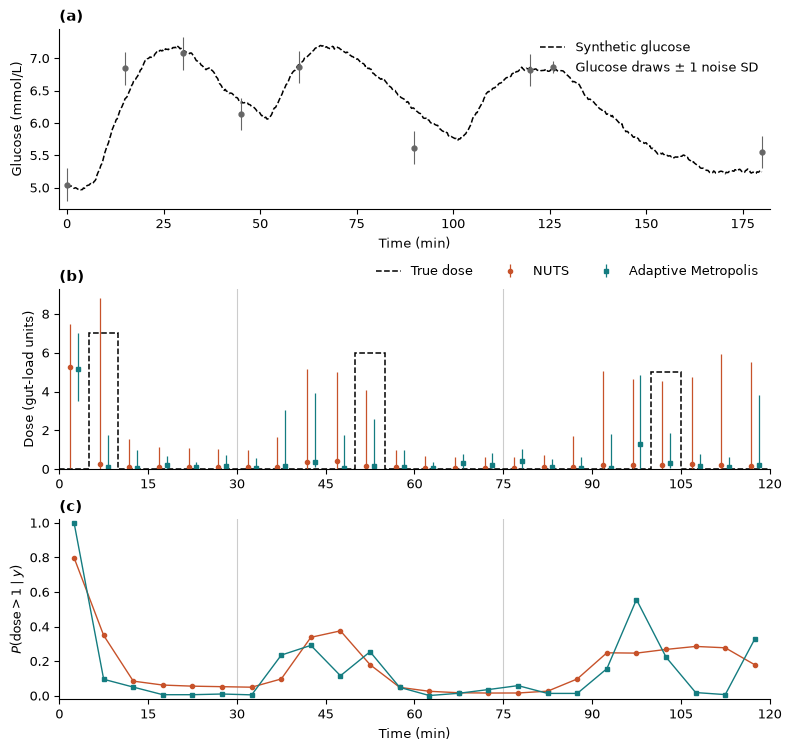

In [10]:
COLORS = {"NUTS": "#c7522a", "Adaptive Metropolis": "#147c80"}
centers = np.asarray(BIN_EDGES[:-1]) + BIN_MINUTES / 2

with plt.rc_context({
    "font.size": 9, "axes.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "legend.frameon": False,
    "xtick.direction": "out", "ytick.direction": "out",
}):
    fig, axes = plt.subplots(3, 1, figsize=(7.8, 7.4), layout="constrained")
    glucose, doses, exceedance = axes
    glucose.plot(sim_times, true_states[:, 0], "--", color="black", lw=1.1, label="Synthetic glucose")
    glucose.errorbar(
        OBS_TIMES, observations[:, 0], yerr=OBS_SD, fmt="o", color="#666666",
        ms=3.5, lw=0.8, label="Glucose draws ± 1 noise SD",
    )
    glucose.set(xlim=(-2, 182), xlabel="Time (min)", ylabel="Glucose (mmol/L)")
    glucose.legend(loc="upper right")

    doses.stairs(TRUE_DOSE, BIN_EDGES, linestyle="--", color="black", lw=1.1, label="True dose")
    for method, offset, marker in zip(METHODS, (-0.65, 0.65), ("o", "s"), strict=True):
        bins = comparison.xs(method, level="sampler").loc[bin_names]
        doses.errorbar(
            centers + offset, bins["median"],
            yerr=[bins["median"] - bins["q05"], bins["q95"] - bins["median"]],
            fmt=marker, color=COLORS[method], ms=3, lw=0.9, label=method,
        )
        probability = (dose_draws[method] > DOSE_THRESHOLD).mean(axis=(0, 1))
        exceedance.plot(centers, probability, marker=marker, color=COLORS[method], ms=3, lw=1)

    for ax in (doses, exceedance):
        ax.set_xlim(0, 120)
        ax.set_xticks(np.arange(0, 121, 15))
    for edge in (30, 75):
        for ax in (doses, exceedance):
            ax.axvline(edge, color="#cccccc", lw=0.8, zorder=0)
    doses.set(ylabel="Dose (gut-load units)", ylim=(0, None))
    doses.legend(loc="lower right", bbox_to_anchor=(1, 1), ncols=3)
    exceedance.set(xlabel="Time (min)", ylabel=r"$P(\mathrm{dose}>1\mid y)$", ylim=(-0.02, 1.02))
    for ax, panel in zip(axes, ("(a)", "(b)", "(c)"), strict=True):
        ax.set_title(panel, loc="left", fontweight="bold")

    fig.savefig(OUT / "feeding_recovery.png", dpi=300)
    fig.savefig(OUT / "feeding_recovery.pdf")
    plt.show()

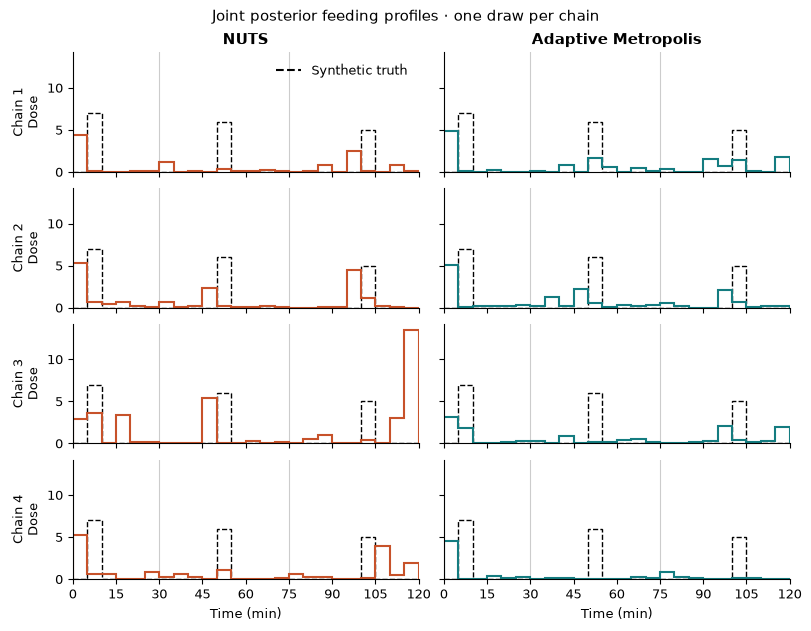

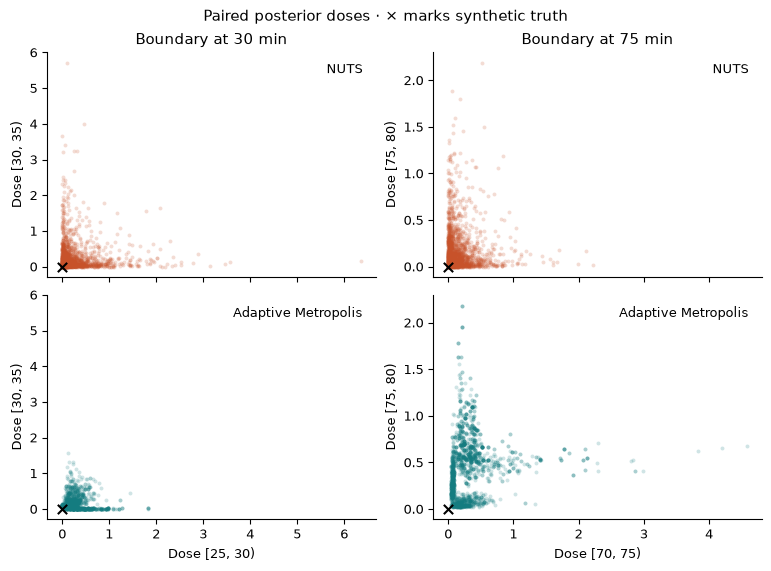

In [11]:
from matplotlib.lines import Line2D

colors = {"NUTS": "#c7522a", "Adaptive Metropolis": "#147c80"}
edges = np.asarray(BIN_EDGES)
truth = np.asarray(TRUE_DOSE)
boundaries = (30, 75)
rng = np.random.default_rng(2026)

style = {
    "font.size": 9,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "xtick.direction": "out",
    "ytick.direction": "out",
}

with plt.rc_context(style):
    n_chains = dose_draws[METHODS[0]].shape[0]
    fig, axes = plt.subplots(
        n_chains,
        len(METHODS),
        figsize=(8, 1.35 * n_chains + 0.8),
        sharex=True,
        sharey=True,
        squeeze=False,
        layout="constrained",
    )

    for col, method in enumerate(METHODS):
        draws = dose_draws[method]
        axes[0, col].set_title(method, fontweight="bold")
        for chain, ax in enumerate(axes[:, col]):
            draw = rng.integers(draws.shape[1])
            ax.stairs(truth, edges, color="black", linestyle="--", lw=1)
            ax.stairs(draws[chain, draw], edges, color=colors[method], lw=1.5)
            for boundary in boundaries:
                ax.axvline(boundary, color="#cccccc", lw=0.8, zorder=0)
            if col == 0:
                ax.set_ylabel(f"Chain {chain + 1}\nDose")
        axes[-1, col].set(
            xlabel="Time (min)",
            xlim=(0, edges[-1]),
            ylim=(0, None),
            xticks=np.arange(0, edges[-1] + 1, 15),
        )

    fig.suptitle("Joint posterior feeding profiles · one draw per chain")
    axes[0, 0].legend(
        handles=[Line2D([], [], color="black", ls="--", label="Synthetic truth")],
        loc="upper right",
    )
    fig.savefig(OUT / "feeding_joint_draws.png", dpi=300)
    fig.savefig(OUT / "feeding_joint_draws.pdf")
    plt.show()

    fig, axes = plt.subplots(
        len(METHODS),
        len(boundaries),
        figsize=(7.6, 5.6),
        sharex="col",
        sharey="col",
        layout="constrained",
    )
    for col, boundary in enumerate(boundaries):
        right = np.searchsorted(edges, boundary)
        left = right - 1
        axes[0, col].set_title(f"Boundary at {boundary} min")
        for row, method in enumerate(METHODS):
            ax = axes[row, col]
            pairs = dose_draws[method][..., [left, right]].reshape(-1, 2)
            keep = rng.choice(len(pairs), size=min(2000, len(pairs)), replace=False)
            ax.scatter(
                pairs[keep, 0],
                pairs[keep, 1],
                s=8,
                color=colors[method],
                alpha=0.20,
                linewidths=0,
            )
            ax.scatter(
                truth[left],
                truth[right],
                s=45,
                marker="x",
                color="black",
                zorder=3,
            )
            ax.text(0.96, 0.95, method, transform=ax.transAxes, ha="right", va="top")
            ax.set_ylabel(f"Dose [{boundary}, {edges[right + 1]:g})")
        axes[-1, col].set_xlabel(f"Dose [{edges[left]:g}, {boundary})")

    fig.suptitle("Paired posterior doses · × marks synthetic truth")
    fig.savefig(OUT / "feeding_boundary_pairs.png", dpi=300)
    fig.savefig(OUT / "feeding_boundary_pairs.pdf")
    plt.show()


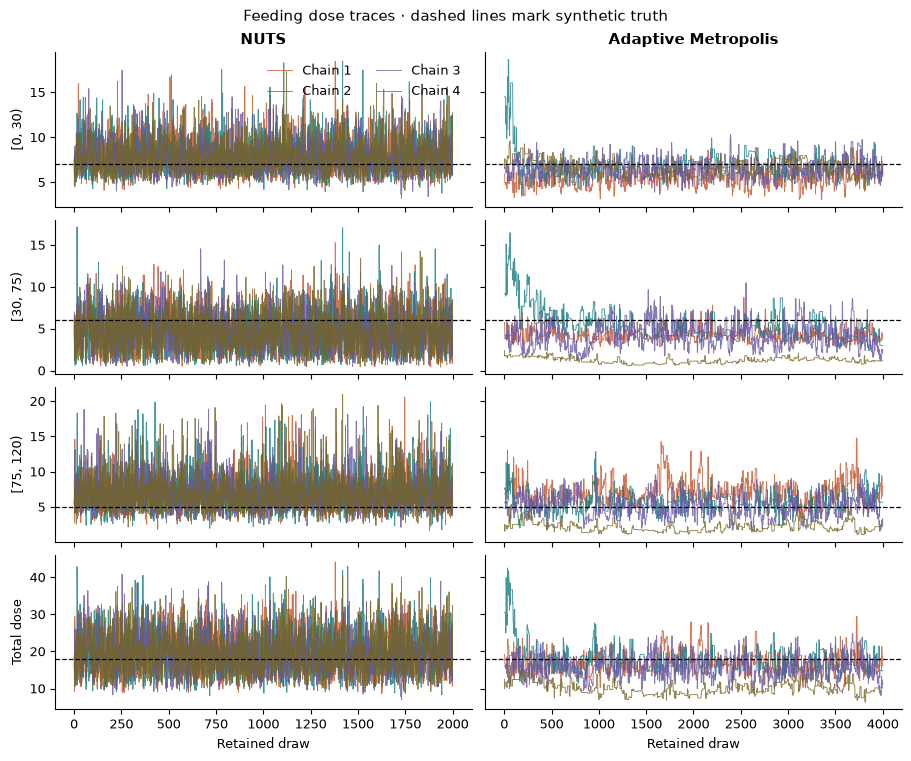

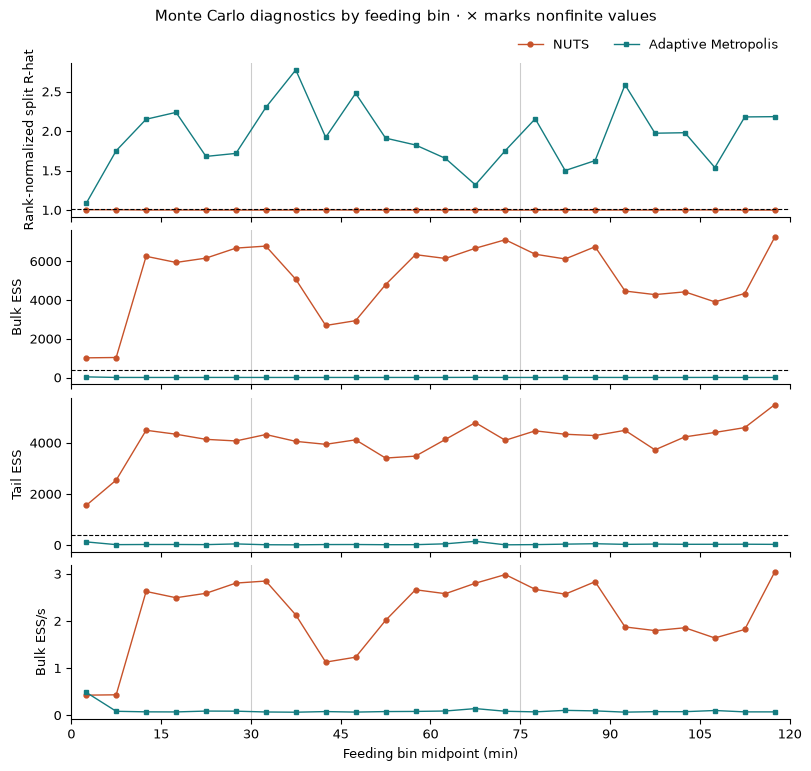

NUTS divergences by chain: [0, 1, 0, 0]


In [12]:
method_colors = {"NUTS": "#c7522a", "Adaptive Metropolis": "#147c80"}
chain_colors = ("#c7522a", "#147c80", "#6756a2", "#766422")
plot_style = {
    "font.size": 9,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "xtick.direction": "out",
    "ytick.direction": "out",
}

with plt.rc_context(plot_style):
    labels = [*window_masks, "Total dose"]
    fig, axes = plt.subplots(
        len(labels),
        len(METHODS),
        figsize=(9, 7.5),
        sharex="col",
        sharey="row",
        layout="constrained",
    )

    for col, method in enumerate(METHODS):
        dose = dose_draws[method]
        series = {
            label: dose[..., mask].sum(axis=-1) for label, mask in window_masks.items()
        }
        series["Total dose"] = dose.sum(axis=-1)
        axes[0, col].set_title(method, fontweight="bold")

        for row, label in enumerate(labels):
            ax = axes[row, col]
            for chain, values in enumerate(series[label]):
                ax.plot(
                    np.arange(1, len(values) + 1),
                    values,
                    color=chain_colors[chain % len(chain_colors)],
                    lw=0.65,
                    alpha=0.8,
                    label=f"Chain {chain + 1}",
                )
            ax.axhline(true_by_quantity[label], color="black", ls="--", lw=0.9)
            if col == 0:
                ax.set_ylabel(label)
        axes[-1, col].set_xlabel("Retained draw")

    axes[0, 0].legend(ncols=2, loc="upper right")
    fig.suptitle("Feeding dose traces · dashed lines mark synthetic truth")
    fig.savefig(OUT / "feeding_mc_traces.png", dpi=300)
    fig.savefig(OUT / "feeding_mc_traces.pdf")
    plt.show()

    centers = (np.asarray(BIN_EDGES[:-1]) + np.asarray(BIN_EDGES[1:])) / 2
    metrics = [
        ("rank-normalized split R-hat", "Rank-normalized split R-hat", 1.01),
        ("bulk ESS", "Bulk ESS", 400),
        ("tail ESS", "Tail ESS", 400),
        ("bulk ESS/s", "Bulk ESS/s", None),
    ]
    fig, axes = plt.subplots(
        len(metrics),
        1,
        figsize=(8, 7.6),
        sharex=True,
        layout="constrained",
    )

    for ax, (column, label, threshold) in zip(axes, metrics, strict=True):
        for method, marker in zip(METHODS, ("o", "s"), strict=True):
            table = comparison.xs(method, level="sampler").loc[bin_names]
            values = table[column].to_numpy()
            ax.plot(
                centers,
                values,
                color=method_colors[method],
                marker=marker,
                ms=3.5,
                lw=1,
                label=method,
            )
            missing = ~np.isfinite(values)
            if missing.any():
                ax.plot(
                    centers[missing],
                    np.full(missing.sum(), 0.05),
                    "x",
                    transform=ax.get_xaxis_transform(),
                    color=method_colors[method],
                )
        if threshold is not None:
            ax.axhline(threshold, color="black", ls="--", lw=0.8)
        for boundary in (30, 75):
            ax.axvline(boundary, color="#cccccc", lw=0.8, zorder=0)
        ax.set_ylabel(label)

    axes[0].legend(loc="lower right", bbox_to_anchor=(1, 1), ncols=2)
    axes[-1].set(
        xlabel="Feeding bin midpoint (min)",
        xlim=(0, 120),
        xticks=np.arange(0, 121, 15),
    )
    fig.suptitle("Monte Carlo diagnostics by feeding bin · × marks nonfinite values")
    fig.savefig(OUT / "feeding_mc_by_bin.png", dpi=300)
    fig.savefig(OUT / "feeding_mc_by_bin.pdf")
    plt.show()

print("NUTS divergences by chain:", nuts_diagnostics["divergences_per_chain"])
